# ЛР № 2. Балансировка такси по зонам города

Вариант 14

В четырёх зонах есть свободные машины, а в четырёх других их не хватает. Ищу самый дешёвый способ выровнять баланс с учётом лимитов маршрутов.

**Среда выполнения → Выполнить всё** запускает весь расчёт.

In [1]:
%pip install -q numpy==2.3.5 scipy==1.17.0 matplotlib==3.10.8

## Данные

Балансы и направления взяты из шаблона. Тарифы и ёмкости маршрутов немного меняются при генерации.

Читаю `data.json`. Если файла нет, создаю его с `seed=10011`.

In [2]:
import csv
import json
import os
from contextlib import redirect_stderr, redirect_stdout
from ctypes import CDLL
from pathlib import Path
from heapq import heappop, heappush
from io import BytesIO

import numpy as np
from IPython.display import Markdown, display
from IPython.display import Image
from scipy.optimize import linprog

SEED = 10011
TOL = 1e-7
STATUS = {0: "optimal", 1: "limit", 2: "infeasible", 3: "unbounded", 4: "solver_error"}

LAB_DIR = Path.cwd()
if LAB_DIR.name != "lr2":
    LAB_DIR = LAB_DIR / "lr2"
DATA_PATH = LAB_DIR / "data.json"
RESULTS = LAB_DIR / "results"
STAR_RESULTS = RESULTS / "star"


def taxis(rng):
    # Дуги из зон с избытком в зоны с нехваткой и два транзитных маршрута.
    base_arcs = [(1, 5, 25, 19), (1, 6, 35, 40), (1, 7, 40, 24),
                 (2, 5, 35, 24), (2, 6, 40, 26), (2, 7, 40, 55),
                 (3, 5, 35, 47), (3, 6, 15, 20), (3, 7, 35, 30),
                 (1, 2, 15, 13), (5, 7, 18, 14),
                 (4, 8, 25, 23), (4, 5, 12, 53), (2, 8, 16, 45)]
    arcs = [
        {"tail": i, "head": j, "capacity": cap + int(rng.integers(-2, 3)),
         "cost": cost + int(rng.integers(0, 3))}
        for i, j, cap, cost in base_arcs
    ]
    return {"seed": SEED, "balance": [40, 35, 25, 20, -30, -35, -35, -20], "arcs": arcs}


if not DATA_PATH.is_file():
    LAB_DIR.mkdir(parents=True, exist_ok=True)
    rng = np.random.default_rng(np.random.SeedSequence([SEED, 2]))
    DATA_PATH.write_text(
        json.dumps(taxis(rng), ensure_ascii=False, indent=2) + "\n",
        encoding="utf-8",
    )
data = json.loads(DATA_PATH.read_text(encoding="utf-8"))

## Решатель и файлы

HiGHS решает модель. Таблицы и лог записываются в `results`.

In [3]:
def write_csv(folder, name, headers, rows):
    path = folder / f"{name}.csv"
    path.parent.mkdir(exist_ok=True)
    with path.open("w", encoding="utf-8", newline="") as file:
        writer = csv.writer(file)
        writer.writerow(headers)
        writer.writerows(rows)


def write_check(folder, name, result):
    path = folder / f"{name}.json"
    path.write_text(json.dumps(result, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")


def solve_lp(cost, *, label, verbose=True, **kwargs):
    print(f"\n=== {label} ===", flush=True)
    result = linprog(
        cost, method="highs-ds", options={"presolve": True, "disp": verbose}, **kwargs
    )
    print(f"{STATUS.get(result.status, result.status)} | {result.message}", flush=True)
    return result


def require_status(result, *allowed):
    if result.status not in allowed:
        raise RuntimeError(result.message)


def run_with_log(run, data, folder):
    folder.mkdir(parents=True, exist_ok=True)
    with (folder / "solver.log").open("w", encoding="utf-8", buffering=1) as log:
        # HiGHS пишет лог напрямую в stdout, минуя Python.
        stdout_fd = os.dup(1)
        try:
            os.dup2(log.fileno(), 1)
            with redirect_stdout(log), redirect_stderr(log):
                return run(data)
        finally:
            CDLL(None).fflush(None)
            os.dup2(stdout_fd, 1)
            os.close(stdout_fd)


def show_table(path, columns, labels=None, *, scenario=None):
    names = {"optimal": "Оптимум", "infeasible": "Нет допустимого плана",
             "feasible": "Допустим", **(labels or {})}
    with path.open(encoding="utf-8", newline="") as file:
        rows = [[row[key] for key in columns] for row in csv.DictReader(file)
                if scenario is None or row["scenario"] == scenario]

    def format_cell(value):
        if not value:
            return "—"
        try:
            number = float(value)
        except ValueError:
            return names.get(value, value)
        return f"{number:,.3f}".rstrip("0").rstrip(".").replace(",", " ").replace(".", ",")

    table = [list(columns.values()), ["---"] * len(columns)]
    table += [[format_cell(value) for value in row] for row in rows]
    display(Markdown("\n".join("| " + " | ".join(row) + " |" for row in table)))

## Модель

Для каждой зоны исходящий поток минус входящий равен её балансу. Поток по маршруту не может превышать его ёмкость.

In [4]:
def inputs(data):
    arcs = np.array([(arc["tail"], arc["head"]) for arc in data["arcs"]]) - 1
    return (arcs, np.array([arc["cost"] for arc in data["arcs"]]),
            np.array([arc["capacity"] for arc in data["arcs"]]),
            np.array(data["balance"]))


def incidence(arcs, count):
    matrix = np.zeros((count, len(arcs)))
    columns = np.arange(len(arcs))
    matrix[arcs[:, 0], columns] = 1
    matrix[arcs[:, 1], columns] = -1
    return matrix


def solve(arcs, cost, capacity, balance, label):
    matrix = incidence(arcs, len(balance))
    # Последняя строка баланса следует из остальных и суммы b = 0.
    if abs(balance.sum()) > TOL:
        raise ValueError("Zone balances must sum to zero")
    return solve_lp(cost, label=label, A_eq=matrix[:-1], b_eq=balance[:-1],
                    bounds=np.column_stack((np.zeros(len(arcs)), capacity)))

## Проверка плана

В NumPy отдельно проверяю ограничения и пересчитываю стоимость. Допуск — $10^{-7}$.

In [5]:
def max_violation(values):
    return float(np.max(values, initial=0))


def verify_objective(checks, expected, actual):
    checks["objective_recomputed"] = float(actual)
    checks["objective_error"] = float(abs(expected - actual))
    if any(value > TOL for key, value in checks.items() if key != "objective_recomputed"):
        raise ValueError(f"Independent check failed: {checks}")
    return checks


def verify(flow, arcs, cost, capacity, balance, objective):
    net = np.zeros(len(balance))
    np.add.at(net, arcs[:, 0], flow)
    np.add.at(net, arcs[:, 1], -flow)
    checks = {
        "zone_balance": max_violation(abs(net - balance)),
        "arc_upper": max_violation(flow - capacity),
        "arc_lower": max_violation(-flow),
    }
    return verify_objective(checks, objective, np.dot(cost, flow)), net


def shortest_delivery(arcs, cost, spare, need):
    queue = [(0, int(source), (), int(source)) for source in np.flatnonzero(need > TOL)]
    best = set()
    while queue:
        tariff, source, path, node = heappop(queue)
        if node in best:
            continue
        best.add(node)
        if need[node] < -TOL:
            return source, node, path
        for index in np.flatnonzero((arcs[:, 0] == node) & (spare > TOL)):
            head = int(arcs[index, 1])
            heappush(queue, (tariff + cost[index], source, (*path, index), head))
    raise ValueError("Greedy routing cannot satisfy remaining demand")


def greedy(arcs, cost, capacity, balance):
    spare, need = capacity.astype(float), balance.astype(float)
    flow = np.zeros(len(arcs))
    while np.max(need) > TOL:
        source, target, path = shortest_delivery(arcs, cost, spare, need)
        edges = list(path)
        amount = min(need[source], -need[target], *spare[edges])
        need[source] -= amount
        need[target] += amount
        flow[edges] += amount
        spare[edges] -= amount
    return flow


def draw_network(arcs, capacity, flow, balance):
    import matplotlib.pyplot as plt

    pos = np.array([(0, 3), (0, 2), (0, 1), (0, 0),
                    (5, 3), (5, 2), (5, 1), (5, 0)])
    labels = [(1.10, 3.09), (1.37, 2.78), (2.1, 2.25), (2.05, 2.49),
              (4.37, 2.08), (1.20, 1.72), (0.79, 1.37), (3.95, 1.83),
              (2.70, 0.93), (-0.42, 2.51), (5.69, 2.03), (2.9, -0.10),
              (3.85, 2.35), (3.81, 0.47)]
    fig, ax = plt.subplots(figsize=(7.1, 4.25))
    for e, ((i, j), (lx, ly)) in enumerate(zip(arcs, labels)):
        active = flow[e] > TOL
        bend = {9: 0.22, 10: -0.48}.get(e, 0)
        ax.annotate("", xy=pos[j], xytext=pos[i],
                    arrowprops=dict(arrowstyle="-|>", color="#171717" if active else "#7d7d7d",
                                    linestyle="-" if active else "--",
                                    linewidth=1.45 if active else 0.8, shrinkA=14, shrinkB=14,
                                    connectionstyle=f"arc3,rad={bend}"))
        ax.text(lx, ly, f"{flow[e]:g}/{capacity[e]:g}", ha="center", va="center",
                fontsize=10, zorder=3, bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none"))
    for k, (x, y) in enumerate(pos):
        ax.scatter(x, y, s=620, facecolor="white", edgecolor="#171717", linewidth=1.2, zorder=4)
        ax.text(x, y, f"Z{k + 1}", ha="center", va="center", zorder=5)
        ax.text(x - 0.3 if k < 4 else x + 0.32, y + 0.23, f"{balance[k]:+g}",
                ha="right" if k < 4 else "left", fontsize=10, zorder=5)
    ax.set(xlim=(-0.98, 6.10), ylim=(-0.33, 3.49))
    ax.axis("off")
    fig.savefig(RESULTS / "network.pdf", bbox_inches="tight", pad_inches=0.03)
    plt.close(fig)
    return fig

## Что меняю в сценариях

Сравниваю базовый план, перегрузку и отказ самой загруженной дуги и рост спроса на 20%. На исходных данных также запускаю жадную эвристику.

In [6]:
def run_lab(data):
    arcs, cost, capacity, balance = inputs(data)
    base = solve(arcs, cost, capacity, balance, "base")
    require_status(base, 0)
    # При одинаковой загрузке в процентах выбираем больший поток.
    busiest = max(range(len(arcs)), key=lambda i: (base.x[i] / capacity[i], base.x[i], -i))
    congested, failed = capacity.astype(float), capacity.copy()
    congested[busiest] *= 0.75
    failed[busiest] = 0
    growth = balance * 1.2
    summary, solution, arc_rows, node_rows, checks = [], [], [], [], {}
    base_cost = base.fun
    for name, cap, b, result in [
        ("base", capacity, balance, base),
        ("congestion", congested, balance, None),
        ("growth", capacity, growth, None),
        ("failure", failed, balance, None),
    ]:
        if result is None:
            result = solve(arcs, cost, cap, b, name)
        require_status(result, 0)
        summary.append([name, cap[busiest], -b[b < 0].sum(), STATUS[result.status], result.fun,
                        result.fun - base_cost, result.nit])
        checks[name], net = verify(result.x, arcs, cost, cap, b, result.fun)
        potentials = np.r_[result.eqlin.marginals, 0]
        for k, b_k in enumerate(b):
            node_rows.append([name, k + 1, b_k, net[k], net[k] - b_k, potentials[k]])
        for e, (i, j) in enumerate(arcs):
            solution.append([name, i + 1, j + 1, cap[e], result.x[e], cost[e], cost[e] * result.x[e]])
            if name == "base":
                arc_rows.append([i + 1, j + 1, cap[e] - result.x[e], result.upper.marginals[e]])
    heuristic = greedy(arcs, cost, capacity, balance)
    greedy_cost = cost @ heuristic
    checks["greedy"], _ = verify(heuristic, arcs, cost, capacity, balance, greedy_cost)
    summary.append(["greedy", capacity[busiest], -balance[balance < 0].sum(), "feasible",
                    greedy_cost, greedy_cost - base_cost, ""])
    for e, (i, j) in enumerate(arcs):
        solution.append(["greedy", i + 1, j + 1, capacity[e], heuristic[e], cost[e],
                         cost[e] * heuristic[e]])
    write_csv(RESULTS, "scenarios",
              ["scenario", "busiest_arc_capacity", "demand", "status", "cost", "delta", "iterations"],
              summary)
    write_csv(RESULTS, "solution", ["scenario", "tail", "head", "capacity", "flow", "tariff", "cost"],
              solution)
    write_csv(RESULTS, "nodes", ["scenario", "zone", "balance", "net_flow", "error", "potential"],
              node_rows)
    write_csv(RESULTS, "arc_marginals", ["tail", "head", "slack", "marginal"], arc_rows)
    write_check(RESULTS, "checks", checks)
    return draw_network(arcs, capacity, base.x, balance)


figure = run_with_log(run_lab, data, RESULTS)

## Что получилось

На схеме рядом с каждой дугой указан поток и её ёмкость. Планы, балансы по зонам и теневые цены сохранены в `results`.

| Сценарий | Спрос, маш. | Статус | Стоимость, у. е. | Прирост, у. е. |
| --- | --- | --- | --- | --- |
| Базовый | 120 | Оптимум | 3 000 | 0 |
| Перегрузка | 120 | Оптимум | 3 037,5 | 37,5 |
| Рост спроса | 144 | Оптимум | 3 630 | 630 |
| Отказ дуги | 120 | Оптимум | 3 262 | 262 |
| Жадный план | 120 | Допустим | 3 088 | 88 |

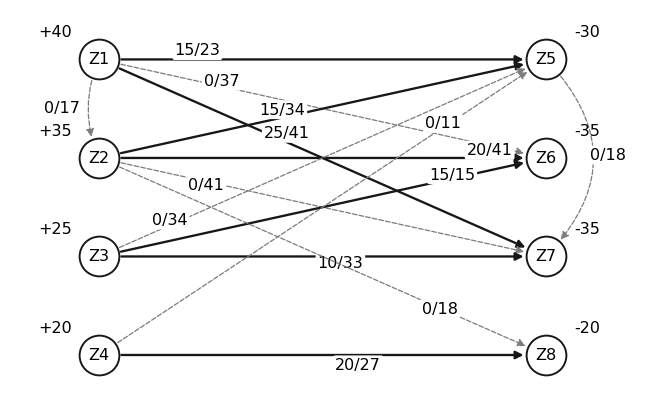

Максимальное расхождение при пересчёте стоимости: 0.


In [7]:
show_table(
    RESULTS / "scenarios.csv",
    {"scenario": "Сценарий", "demand": "Спрос, маш.", "status": "Статус",
     "cost": "Стоимость, у. е.", "delta": "Прирост, у. е."},
    {"base": "Базовый", "congestion": "Перегрузка", "growth": "Рост спроса",
     "failure": "Отказ дуги", "greedy": "Жадный план"},
)

with BytesIO() as buffer:
    figure.savefig(buffer, format="png", dpi=115, bbox_inches="tight")
    display(Image(data=buffer.getvalue()))

checks = json.loads((RESULTS / "checks.json").read_text(encoding="utf-8"))
error = max(item["objective_error"] for item in checks.values() if "objective_error" in item)
print(f"Максимальное расхождение при пересчёте стоимости: {error:.2g}.")

## Со звёздочкой. Двойственная задача

Решаю прямую и двойственную задачи отдельно. Сверяю цели, двойственные ограничения и дополняющую нежёсткость.

In [8]:
def solve_dual(arcs, cost, capacity, balance):
    count = len(balance)
    matrix = incidence(arcs, count)
    bounds = [(None, None)] * (count - 1) + [(0, 0)] + [(0, None)] * len(cost)
    return solve_lp(np.r_[-balance, capacity], label="dual: maximize b*p - u*l",
                    A_ub=np.column_stack((matrix.T, -np.eye(len(cost)))),
                    b_ub=cost, bounds=bounds)


def run_star(data):
    arcs, cost, capacity, balance = inputs(data)
    primal = solve(arcs, cost, capacity, balance, "primal: base")
    dual = solve_dual(arcs, cost, capacity, balance)
    require_status(primal, 0)
    require_status(dual, 0)
    pi, mu = np.split(dual.x, [len(balance)])
    tail, head = arcs.T
    reduced_cost = cost - pi[tail] + pi[head] + mu
    objective = balance @ pi - capacity @ mu
    checks, _ = verify(primal.x, arcs, cost, capacity, balance, primal.fun)
    checks.update({
        "dual_feasibility": max(max_violation(-reduced_cost), max_violation(-mu)),
        "arc_lower_complementarity": max_violation(abs(reduced_cost * primal.x)),
        "arc_upper_complementarity": max_violation(abs(mu * (capacity - primal.x))),
        "dual_objective_error": abs(objective + dual.fun),
        "duality_gap": abs(primal.fun - objective),
    })
    assert all(value <= TOL for key, value in checks.items() if key != "objective_recomputed")
    checks["dual_objective"] = float(objective)
    write_check(STAR_RESULTS, "checks", checks)
    write_csv(STAR_RESULTS, "potentials", ["zone", "balance", "potential", "contribution"],
              ((i + 1, b, p, b * p) for i, (b, p) in enumerate(zip(balance, pi))))
    write_csv(STAR_RESULTS, "arc_multipliers", ["tail", "head", "capacity", "flow", "mu", "reduced_cost"],
              ((i + 1, j + 1, u, x, m, r)
               for (i, j), u, x, m, r in zip(arcs, capacity, primal.x, mu, reduced_cost)))


run_with_log(run_star, data, STAR_RESULTS)

show_table(
    STAR_RESULTS / "potentials.csv",
    {"zone": "Зона", "balance": "Баланс, маш.", "potential": "Потенциал, у. е./маш.",
     "contribution": "Вклад, у. е."},
)
checks = json.loads((STAR_RESULTS / "checks.json").read_text(encoding="utf-8"))
print(f"Прямая и двойственная цели: {checks['objective_recomputed']:g} и "
      f"{checks['dual_objective']:g} у. е.")

| Зона | Баланс, маш. | Потенциал, у. е./маш. | Вклад, у. е. |
| --- | --- | --- | --- |
| 1 | 40 | 42 | 1 680 |
| 2 | 35 | 45 | 1 575 |
| 3 | 25 | 48 | 1 200 |
| 4 | 20 | 24 | 480 |
| 5 | -30 | 21 | -630 |
| 6 | -35 | 17 | -595 |
| 7 | -35 | 16 | -560 |
| 8 | -20 | 0 | -0 |

Прямая и двойственная цели: 3000 и 3000 у. е.
